# ATM Cash Demand Prediction Using Machine Learning
**Objective:** Predict the next day's cash demand of an ATM from historical data, so cash can be replenished in the right amount at the right time.

| | |
|---|---|
| Learning type | Supervised Learning |
| Problem type | Regression |
| Primary model | Multiple Linear Regression |
| Comparison models | Decision Tree, Bagging, Random Forest |
| Target | `Cash_Demand_Next_Day` (₹) |

**Workflow:** Data Collection → Preprocessing → Feature Selection → Train-Test Split → Model Training → Prediction → Replenishment

## Import required libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.decomposition import PCA
import joblib

# Upload and load ATM dataset

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving atm_cash_management_dataset.csv to atm_cash_management_dataset.csv


In [ ]:
df = pd.read_csv('atm_cash_management_dataset.csv')

#Basic information

In [ ]:
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (5658, 13)


,ATM_ID,Date,Day_of_Week,Time_of_Day,Total_Withdrawals,Total_Deposits,Location_Type,Holiday_Flag,Special_Event_Flag,Previous_Day_Cash_Level,Weather_Condition,Nearby_Competitor_ATMs,Cash_Demand_Next_Day
0,ATM_0041,2022-04-25,Monday,Morning,57450,9308,Standalone,0,0,112953,Rainy,5,44165
1,ATM_0007,2023-11-24,Friday,Morning,72845,17896,Supermarket,0,0,115348,Clear,0,41249
2,ATM_0014,2022-08-27,Saturday,Morning,42957,12712,Supermarket,0,0,90731,Cloudy,1,29901
3,ATM_0029,2023-08-27,Sunday,Evening,43014,1375,Mall,0,0,88754,Rainy,5,44155
4,ATM_0028,2022-12-15,Thursday,Evening,36379,2938,Bank Branch,0,0,129312,Snowy,0,29784
5,ATM_0006,2023-01-25,Wednesday,Morning,46613,7278,Standalone,1,0,102218,Snowy,0,49358
6,ATM_0047,2023-04-16,Sunday,Morning,40990,8541,Gas Station,0,0,87965,Snowy,5,28407
7,ATM_0040,2023-01-06,Friday,Afternoon,77784,14112,Mall,0,0,75583,Rainy,2,61200
8,ATM_0006,2022-08-27,Saturday,Morning,30077,10984,Gas Station,0,0,114769,Snowy,1,18557
9,ATM_0024,2022-12-30,Friday,Afternoon,52570,9421,Standalone,0,0,93977,Clear,4,44240


In [ ]:
df.shape

(5658, 13)

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5658 entries, 0 to 5657
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ATM_ID                   5658 non-null   object
 1   Date                     5658 non-null   object
 2   Day_of_Week              5658 non-null   object
 3   Time_of_Day              5658 non-null   object
 4   Total_Withdrawals        5658 non-null   int64 
 5   Total_Deposits           5658 non-null   int64 
 6   Location_Type            5658 non-null   object
 7   Holiday_Flag             5658 non-null   int64 
 8   Special_Event_Flag       5658 non-null   int64 
 9   Previous_Day_Cash_Level  5658 non-null   int64 
 10  Weather_Condition        5658 non-null   object
 11  Nearby_Competitor_ATMs   5658 non-null   int64 
 12  Cash_Demand_Next_Day     5658 non-null   int64 
dtypes: int64(7), object(6)
memory usage: 574.8+ KB
None


In [ ]:
# Display summary statistics
display(df.describe())

,Total_Withdrawals,Total_Deposits,Holiday_Flag,Special_Event_Flag,Previous_Day_Cash_Level,Nearby_Competitor_ATMs,Cash_Demand_Next_Day
count,5658.000000,5658.000000,5658.000000,5658.000000,5658.000000,5658.000000,5658.000000
mean,49808.106928,10129.078473,0.022093,0.096501,100283.994698,2.477731,43085.207494
std,14903.539241,4878.853583,0.146998,0.295303,20122.365608,1.719487,16797.100086
min,1380.000000,0.000000,0.000000,0.000000,23266.000000,0.000000,0.000000
25%,39469.250000,6765.000000,0.000000,0.000000,86533.500000,1.000000,31558.750000
50%,50039.000000,10048.000000,0.000000,0.000000,100276.500000,2.000000,42589.500000
75%,60132.500000,13430.000000,0.000000,0.000000,113956.500000,4.000000,53831.000000
max,107790.000000,32395.000000,1.000000,1.000000,172227.000000,5.000000,114724.000000


#Data preprocessing

In [ ]:
# Display column names and data types
print(df.dtypes)

ATM_ID                     object
Date                       object
Day_of_Week                object
Time_of_Day                object
Total_Withdrawals           int64
Total_Deposits              int64
Location_Type              object
Holiday_Flag                int64
Special_Event_Flag          int64
Previous_Day_Cash_Level     int64
Weather_Condition          object
Nearby_Competitor_ATMs      int64
Cash_Demand_Next_Day        int64
dtype: object


In [ ]:
# Check missing values
print(df.isnull().sum())

ATM_ID                     0
Date                       0
Day_of_Week                0
Time_of_Day                0
Total_Withdrawals          0
Total_Deposits             0
Location_Type              0
Holiday_Flag               0
Special_Event_Flag         0
Previous_Day_Cash_Level    0
Weather_Condition          0
Nearby_Competitor_ATMs     0
Cash_Demand_Next_Day       0
dtype: int64


In [ ]:
# Replace common missing-value markers with NaN
df.replace(["?", " ?", -200], np.nan, inplace=True)

# Fill missing numerical values with the median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the mode
for col in df.select_dtypes(include="object").columns:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
ATM_ID                     0
Date                       0
Day_of_Week                0
Time_of_Day                0
Total_Withdrawals          0
Total_Deposits             0
Location_Type              0
Holiday_Flag               0
Special_Event_Flag         0
Previous_Day_Cash_Level    0
Weather_Condition          0
Nearby_Competitor_ATMs     0
Cash_Demand_Next_Day       0
dtype: int64


In [ ]:
# Feature engineering from the Date column (infographic inputs: month, day of week, weekend indicator)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Month"] = df["Date"].dt.month
df["Month"] = df["Month"].fillna(df["Month"].median())
df["Is_Weekend"] = df["Date"].dt.dayofweek.isin([5, 6]).astype(int)

# ATM_ID and Date are identifiers: one-hot encoding them would create ~800 useless columns
df = df.drop(columns=["ATM_ID", "Date"]).drop_duplicates()

# Outlier treatment: clip extreme values using the IQR rule
for col in ["Total_Withdrawals", "Total_Deposits", "Previous_Day_Cash_Level", "Cash_Demand_Next_Day"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    df[col] = df[col].clip(low, high)
    print(f"{col}: {n_out} outliers clipped")

print("Shape after cleaning:", df.shape)

Total_Withdrawals: 33 outliers clipped
Total_Deposits: 25 outliers clipped
Previous_Day_Cash_Level: 40 outliers clipped
Cash_Demand_Next_Day: 36 outliers clipped
Shape after cleaning: (5658, 13)


In [ ]:
# Convert categorical columns into numerical columns
df = pd.get_dummies(df, drop_first=True, dtype=int)

print("Shape after encoding:", df.shape)
display(df.head())

Shape after encoding: (5658, 25)


,Total_Withdrawals,Total_Deposits,Holiday_Flag,Special_Event_Flag,Previous_Day_Cash_Level,Nearby_Competitor_ATMs,Cash_Demand_Next_Day,Month,Is_Weekend,Day_of_Week_Monday,...,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Location_Type_Gas Station,Location_Type_Mall,Location_Type_Standalone,Location_Type_Supermarket,Weather_Condition_Cloudy,Weather_Condition_Rainy,Weather_Condition_Snowy
0,57450.0,9308.0,0,0,112953,5,44165.0,4,0,1,...,0,1,0,0,0,1,0,0,1,0
1,72845.0,17896.0,0,0,115348,0,41249.0,11,0,0,...,0,1,0,0,0,0,1,0,0,0
2,42957.0,12712.0,0,0,90731,1,29901.0,8,1,0,...,0,1,0,0,0,0,1,1,0,0
3,43014.0,1375.0,0,0,88754,5,44155.0,8,1,0,...,1,0,0,0,1,0,0,0,1,0
4,36379.0,2938.0,0,0,129312,0,29784.0,12,0,0,...,1,0,0,0,0,0,0,0,0,1


#Simple and Multiple Linear Regression

In [ ]:
# Display the available columns
print(df.columns.tolist())

['Total_Withdrawals', 'Total_Deposits', 'Holiday_Flag', 'Special_Event_Flag', 'Previous_Day_Cash_Level', 'Nearby_Competitor_ATMs', 'Cash_Demand_Next_Day', 'Month', 'Is_Weekend', 'Day_of_Week_Monday', 'Day_of_Week_Saturday', 'Day_of_Week_Sunday', 'Day_of_Week_Thursday', 'Day_of_Week_Tuesday', 'Day_of_Week_Wednesday', 'Time_of_Day_Evening', 'Time_of_Day_Morning', 'Time_of_Day_Night', 'Location_Type_Gas Station', 'Location_Type_Mall', 'Location_Type_Standalone', 'Location_Type_Supermarket', 'Weather_Condition_Cloudy', 'Weather_Condition_Rainy', 'Weather_Condition_Snowy']


In [ ]:
# Select the target column
target = "Cash_Demand_Next_Day"

# Select input features (calendar features Month / Is_Weekend come from the Date column)
features = [
    "Total_Withdrawals",
    "Total_Deposits",
    "Holiday_Flag",
    "Special_Event_Flag",
    "Previous_Day_Cash_Level",
    "Nearby_Competitor_ATMs",
    "Month",
    "Is_Weekend"
]

# Separate input and output
X = df[features]
y = df[target]

# Remove rows with missing values
data = df[features + [target]].dropna()

X = data[features]
y = data[target]

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Target:", target)

Training data: (4526, 8)
Testing data: (1132, 8)
Target: Cash_Demand_Next_Day


In [ ]:
# Use Total_Withdrawals as the single input feature
feature = "Total_Withdrawals"

simple_model = LinearRegression()
simple_model.fit(X_train[[feature]], y_train)

# Predict next-day cash demand
simple_pred = simple_model.predict(X_test[[feature]])

# Evaluate the model
print("MAE:", mean_absolute_error(y_test, simple_pred))
print("MSE:", mean_squared_error(y_test, simple_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_pred)))
print("R2 Score:", r2_score(y_test, simple_pred))

MAE: 5922.888273674317
MSE: 52478143.85570385
RMSE: 7244.179998847617
R2 Score: 0.8122119608739105


In [ ]:
# Train using all input features
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Predict next-day cash demand
multiple_pred = multiple_model.predict(X_test)

# Evaluate the model
print("MAE:", mean_absolute_error(y_test, multiple_pred))
print("MSE:", mean_squared_error(y_test, multiple_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, multiple_pred)))
print("R2 Score:", r2_score(y_test, multiple_pred))

MAE: 4974.554031356059
MSE: 36100562.434180215
RMSE: 6008.374358691393
R2 Score: 0.870817575989269


In [ ]:
# Compare regression models
comparison_reg = pd.DataFrame({
    "Model": ["Simple Regression", "Multiple Regression"],
    "MAE": [
        mean_absolute_error(y_test, simple_pred),
        mean_absolute_error(y_test, multiple_pred)
    ],
    "MSE": [
        mean_squared_error(y_test, simple_pred),
        mean_squared_error(y_test, multiple_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, simple_pred)),
        np.sqrt(mean_squared_error(y_test, multiple_pred))
    ],
    "R2 Score": [
        r2_score(y_test, simple_pred),
        r2_score(y_test, multiple_pred)
    ]
})

display(comparison_reg)

,Model,MAE,MSE,RMSE,R2 Score
0,Simple Regression,5922.888274,5.247814e+07,7244.179999,0.812212
1,Multiple Regression,4974.554031,3.610056e+07,6008.374359,0.870818


#Extra: High vs Low demand classification (Logistic Regression, KNN, Naive Bayes)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import make_pipeline

# Classification needs a categorical target: is tomorrow's demand HIGH (1) or LOW (0)?
# (split at the median demand, so the two classes are balanced)
y_class = (y > y.median()).astype(int)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

models_cls = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Gaussian Naive Bayes": GaussianNB()
}

for name, model in models_cls.items():
    model.fit(Xc_train, yc_train)
    y_pred = model.predict(Xc_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(yc_test, y_pred))
    print("Precision:", precision_score(yc_test, y_pred, zero_division=0))
    print("Recall:", recall_score(yc_test, y_pred, zero_division=0))
    print("F1 Score:", f1_score(yc_test, y_pred, zero_division=0))
    print("Confusion Matrix:\n", confusion_matrix(yc_test, y_pred))
    print("Classification Report:\n", classification_report(yc_test, y_pred, zero_division=0))


 Logistic Regression
Accuracy: 0.8657243816254417
Precision: 0.8683274021352313
Recall: 0.8621908127208481
F1 Score: 0.8652482269503546
Confusion Matrix:
 [[492  74]
 [ 78 488]]
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.87      0.87       566
           1       0.87      0.86      0.87       566

    accuracy                           0.87      1132
   macro avg       0.87      0.87      0.87      1132
weighted avg       0.87      0.87      0.87      1132


 KNN
Accuracy: 0.8418727915194346
Precision: 0.8400702987697716
Recall: 0.8445229681978799
F1 Score: 0.8422907488986784
Confusion Matrix:
 [[475  91]
 [ 88 478]]
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.84      0.84       566
           1       0.84      0.84      0.84       566

    accuracy                           0.84      1132
   macro avg       0.84      0.84      0.84      1132
weighted av

#K-Means Elbow Method

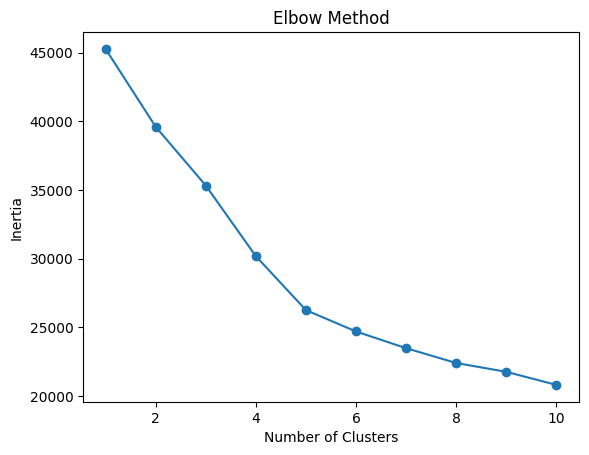

In [ ]:
# Scale features for clustering
cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(X)

# Calculate inertia for different cluster counts
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_cluster)
    inertia.append(model.inertia_)

# Plot elbow graph
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

#K-Means clustering

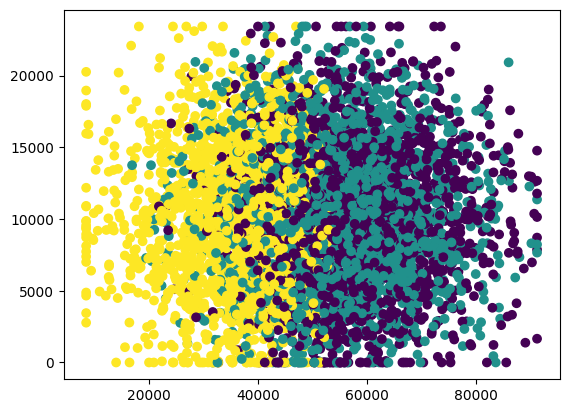

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

kmeans = KMeans(n_clusters=3, random_state=42)
df["KMeans_Cluster"] = kmeans.fit_predict(X)

plt.scatter(X["Total_Withdrawals"], X["Total_Deposits"],
            c=df["KMeans_Cluster"])
plt.show()

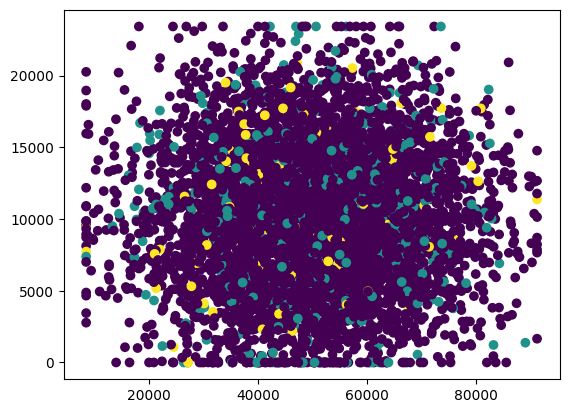

In [ ]:
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

gmm = GaussianMixture(n_components=3, random_state=42)
df["GMM_Cluster"] = gmm.fit_predict(X)

plt.scatter(X["Total_Withdrawals"], X["Total_Deposits"],
            c=df["GMM_Cluster"])
plt.show()

#Decision Tree, Bagging and Random Forest

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score

models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Bagging": BaggingRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("\n", name)
    print("MAE:", mean_absolute_error(y_test, pred))
    print("MSE:", mean_squared_error(y_test, pred))
    print("RMSE:", mean_squared_error(y_test, pred) ** 0.5)
    print("R2 Score:", r2_score(y_test, pred))
    # WAPE (weighted MAPE) is used because some days have 0 demand, which breaks plain MAPE
    print("WAPE (%):", np.abs(y_test - pred).sum() / np.abs(y_test).sum() * 100)


 Decision Tree
MAE: 7122.9613515901065
MSE: 81543948.15865172
RMSE: 9030.168777971523
R2 Score: 0.7082027487592183
WAPE (%): 16.476916733353708

 Bagging
MAE: 5523.145991607773
MSE: 46371486.180608295
RMSE: 6809.661238314891
R2 Score: 0.8340640536913251
WAPE (%): 12.776205305334425

 Random Forest
MAE: 5241.972725265017
MSE: 41084955.90807372
RMSE: 6409.754746327953
R2 Score: 0.8529813987176599
WAPE (%): 12.125792047632213


#Cross-validation

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="r2")
    print(name)
    print("Scores:", scores)
    print("Average Score:", scores.mean())

Linear Regression
Scores: [0.86498414 0.8656195  0.87276831 0.86414919 0.85297745]
Average Score: 0.8640997157821104
Decision Tree
Scores: [0.71201904 0.73118133 0.73190975 0.68705393 0.70166861]
Average Score: 0.7127665327430354
Random Forest
Scores: [0.84702194 0.85004711 0.84983443 0.84104172 0.83892956]
Average Score: 0.8453749523071918


#Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(random_state=42)

params = {
    "max_depth": [3, 5, 10],
    "min_samples_split": [2, 5, 10]
}

search = GridSearchCV(model, params, cv=5, scoring="r2")
search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
print("Best Score:", search.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_split': 2}
Best Score: 0.8129094959692089


# BEST MODEL

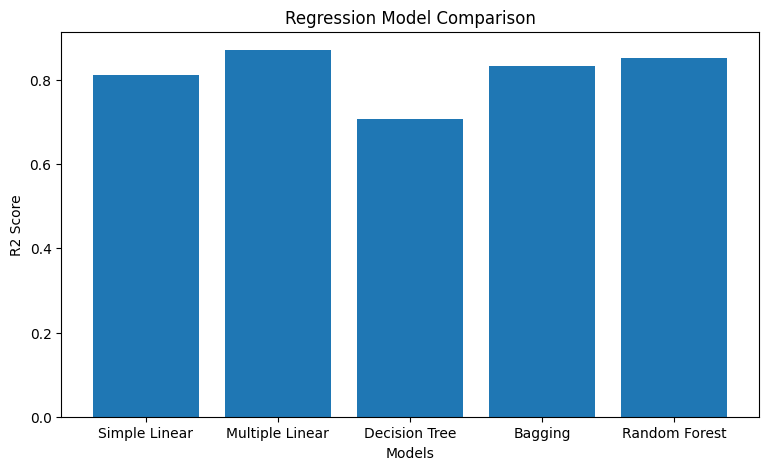

Best Model: Multiple Linear
Best R2 Score: 0.871


In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.metrics import r2_score

features = [
    "Total_Withdrawals",
    "Total_Deposits",
    "Holiday_Flag",
    "Special_Event_Flag",
    "Previous_Day_Cash_Level",
    "Nearby_Competitor_ATMs",
    "Month",
    "Is_Weekend"
]

X = df[features]
y = df["Cash_Demand_Next_Day"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Simple Linear": LinearRegression(),
    "Multiple Linear": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Bagging": BaggingRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

names = []
scores = []

for name, model in models.items():
    if name == "Simple Linear":
        model.fit(
            X_train[["Total_Withdrawals"]], y_train
        )
        pred = model.predict(
            X_test[["Total_Withdrawals"]]
        )
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

    names.append(name)
    scores.append(r2_score(y_test, pred))

plt.figure(figsize=(9, 5))
plt.bar(names, scores)
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.title("Regression Model Comparison")
plt.show()

print("Best Model:", names[scores.index(max(scores))])
print("Best R2 Score:", round(max(scores), 3))

#Save the Model

In [ ]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

features = [
    "Total_Withdrawals",
    "Total_Deposits",
    "Holiday_Flag",
    "Special_Event_Flag",
    "Previous_Day_Cash_Level",
    "Nearby_Competitor_ATMs",
    "Month",
    "Is_Weekend"
]

X = df[features]
y = df["Cash_Demand_Next_Day"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

best_model = LinearRegression()
best_model.fit(X_train, y_train)

predictions = best_model.predict(X_test)

print("Model: Multiple Linear Regression")
print("R2 Score:", round(r2_score(y_test, predictions), 3))

joblib.dump(best_model, "atm_cash_model.pkl")
joblib.dump(features, "atm_features.pkl")

print("Model and features saved successfully!")

Model: Multiple Linear Regression
R2 Score: 0.871
Model and features saved successfully!


# Replenishment Planning
Last step of the workflow: turn the predicted demand into a cash-loading recommendation. A safety buffer covers forecast error (average error of the model is shown above).

In [ ]:
BUFFER = 0.10   # 10% safety stock

demo_rows = X_test.iloc[:5].copy()
plan = pd.DataFrame({
    "Predicted_Demand": best_model.predict(demo_rows).clip(min=0).round(0),
    "Actual_Demand": y_test.iloc[:5].values,
})
plan["Cash_To_Load (+10%)"] = (plan["Predicted_Demand"] * (1 + BUFFER)).round(0)
display(plan)

,Predicted_Demand,Actual_Demand,Cash_To_Load (+10%)
0,44531.0,50335.0,48984.0
1,71746.0,76882.0,78921.0
2,43066.0,49730.0,47373.0
3,30075.0,26431.0,33082.0
4,25001.0,26694.0,27501.0


# Challenges / Limitations
- Unexpected events (festivals, local events, strikes) can change withdrawal patterns
- Historical data may not always represent future behaviour
- Holidays and special days create unusual demand
- Poor data quality or missing data can affect accuracy
- Multiple linear regression assumes linear relationships among variables (compare with Decision Tree / Random Forest above)

#ATM Cash Demand Prediction

In [ ]:

import gradio as gr
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import joblib

# LOAD MODEL
model = joblib.load("atm_cash_model.pkl")
features = joblib.load("atm_features.pkl")

# THEME
theme = gr.themes.Soft(
    primary_hue="blue",
    secondary_hue="sky",
    neutral_hue="slate"
)

# PROFESSIONAL CSS
css = """
.gradio-container {
    max-width: 1600px !important;
    width: 100% !important;
    margin: auto !important;
    padding: 24px !important;
    background: #F3F6FC !important;
    color: #17365D !important;
    font-family: Arial, sans-serif !important;
}

body {
    background: #F3F6FC !important;
}

/* TOP HEADER */
.header {
    background: linear-gradient(135deg, #081A30, #17365D 55%, #2563EB);
    padding: 38px 22px;
    border-radius: 16px;
    text-align: center;
    margin-bottom: 25px;
    border: 1px solid #294D78;
    box-shadow: 0 8px 22px rgba(8, 26, 48, 0.20);
}

.header h1 {
    color: #FFFFFF !important;
    font-size: clamp(24px, 3vw, 36px) !important;
    font-weight: 800 !important;
    letter-spacing: 1px;
    margin: 0 0 12px 0;
}

.header p {
    color: #DCEAFE !important;
    font-size: 15px;
    margin: 0;
}

/* SECTION HEADINGS */
h1, h2, h3, h4 {
    color: #17365D !important;
    font-weight: 700 !important;
}

.section-title {
    color: #17365D !important;
    font-size: 22px !important;
    font-weight: 800 !important;
    border-left: 5px solid #2563EB;
    padding-left: 13px;
    margin: 18px 0 !important;
}

/* INPUT PANEL */
.input-panel {
    background: #FFFFFF !important;
    border: 1px solid #D7E2F0 !important;
    border-radius: 14px !important;
    padding: 22px !important;
    box-shadow: 0 4px 15px rgba(23, 54, 93, 0.06);
    margin-bottom: 16px !important;
}

/* INPUT FIELDS */
input, textarea {
    background: #FFFFFF !important;
    color: #17365D !important;
    border: 1px solid #C7D4E5 !important;
    border-radius: 8px !important;
}

input:focus, textarea:focus {
    border-color: #2563EB !important;
    box-shadow: 0 0 0 3px rgba(37, 99, 235, 0.12) !important;
}

label {
    color: #17365D !important;
    font-weight: 600 !important;
}

.gradio-container input[type="radio"] {
    accent-color: #2563EB !important;
}

/* ALL BUTTONS */
.gradio-container button {
    border-radius: 10px !important;
    min-height: 46px !important;
    font-size: 14px !important;
    font-weight: 700 !important;
    transition: all 0.2s ease !important;
}

/* MAIN PREDICT BUTTON */
.gradio-container button.primary,
.gradio-container button.variant-primary {
    background: linear-gradient(135deg, #17365D, #2563EB) !important;
    color: #FFFFFF !important;
    border: 1px solid #17365D !important;
    box-shadow: 0 5px 13px rgba(37, 99, 235, 0.25) !important;
    letter-spacing: 0.3px !important;
}

.gradio-container button.primary:hover,
.gradio-container button.variant-primary:hover {
    background: linear-gradient(135deg, #081A30, #17365D) !important;
    color: #FFFFFF !important;
    transform: translateY(-2px) !important;
    box-shadow: 0 7px 18px rgba(23, 54, 93, 0.30) !important;
}

/* RESET BUTTON */
.gradio-container button.secondary,
.gradio-container button.variant-secondary {
    background: #FFFFFF !important;
    color: #17365D !important;
    border: 1px solid #A8BCD5 !important;
    box-shadow: 0 2px 6px rgba(23, 54, 93, 0.06);
}

.gradio-container button.secondary:hover,
.gradio-container button.variant-secondary:hover {
    background: #E8F0FC !important;
    color: #17365D !important;
    border-color: #2563EB !important;
}

/* KPI CARDS */
.kpi-grid {
    display: grid;
    grid-template-columns: repeat(5, minmax(0, 1fr));
    gap: 14px;
    margin: 20px 0 25px;
}

.kpi {
    min-height: 120px;
    padding: 18px 12px;
    border-radius: 13px;
    text-align: center;
    display: flex;
    flex-direction: column;
    justify-content: center;
    overflow-wrap: anywhere;
    box-shadow: 0 5px 14px rgba(15, 23, 42, 0.12);
}

.kpi h3 {
    color: #FFFFFF !important;
    font-size: 14px !important;
    line-height: 1.5 !important;
    margin: 0 0 10px !important;
}

.kpi h2 {
    color: #FFFFFF !important;
    font-size: clamp(17px, 1.7vw, 24px) !important;
    font-weight: 800 !important;
    margin: 0 !important;
}

/* CHART PANELS */
.chart-panel {
    background: #FFFFFF !important;
    border: 1px solid #DCE5F0 !important;
    border-radius: 14px !important;
    padding: 12px !important;
    box-shadow: 0 4px 14px rgba(23, 54, 93, 0.06);
    margin-bottom: 14px !important;
}

/* SUMMARY BOX */
.summary-box textarea {
    background: #FFFFFF !important;
    color: #17365D !important;
    border: 1px solid #CBD5E1 !important;
    font-size: 14px !important;
    line-height: 1.8 !important;
}

/* BOTTOM FOOTER */
.footer-note {
    background: linear-gradient(135deg, #081A30, #17365D 70%, #1E40AF);
    color: #FFFFFF !important;
    padding: 24px;
    border: 1px solid #294D78;
    border-left: 6px solid #60A5FA;
    border-radius: 13px;
    margin-top: 25px;
    font-size: 13px;
    line-height: 1.9;
    box-shadow: 0 6px 18px rgba(8, 26, 48, 0.18);
}

.footer-note b {
    color: #93C5FD !important;
    font-size: 15px;
}

/* SEPARATORS */
hr {
    border-color: #D8E2F0 !important;
    margin: 24px 0 !important;
}

/* RESPONSIVE */
@media (max-width: 1100px) {
    .kpi-grid {
        grid-template-columns: repeat(3, minmax(0, 1fr));
    }
}

@media (max-width: 650px) {
    .gradio-container {
        padding: 12px !important;
    }

    .header {
        padding: 26px 14px;
    }

    .kpi-grid {
        grid-template-columns: repeat(2, minmax(0, 1fr));
        gap: 10px;
    }

    .input-panel {
        padding: 14px !important;
    }
}

@media (max-width: 380px) {
    .kpi-grid {
        grid-template-columns: 1fr;
    }
}
"""


# CHART STYLE
def style_chart(fig):
    fig.update_layout(
        template="plotly_white",
        paper_bgcolor="#FFFFFF",
        plot_bgcolor="#F8FAFC",
        font=dict(family="Arial", color="#17365D", size=12),
        title=dict(
            font=dict(size=17, color="#17365D"),
            x=0.03
        ),
        margin=dict(l=40, r=25, t=65, b=45),
        height=360,
        hoverlabel=dict(
            bgcolor="#17365D",
            font_color="#FFFFFF"
        )
    )

    fig.update_xaxes(
        showgrid=False,
        linecolor="#CBD5E1"
    )

    fig.update_yaxes(
        showgrid=True,
        gridcolor="#E2E8F0",
        zerolinecolor="#CBD5E1",
        tickformat=",.0f"
    )

    return fig


# PREDICTION FUNCTION
def predict(withdrawals, deposits, holiday, event,
            cash, competitors, month, weekend):

    values = [
        withdrawals, deposits, holiday, event,
        cash, competitors, month, weekend
    ]

    if any(v is None for v in values):
        raise gr.Error("Please enter all ATM details.")

    if withdrawals < 0 or deposits < 0 or cash < 0:
        raise gr.Error("Amounts cannot be negative.")

    if competitors < 0 or competitors != int(competitors):
        raise gr.Error("Competitor ATMs must be a whole number.")

    if month not in range(1, 13):
        raise gr.Error("Please select a valid month.")

    if holiday not in [0, 1] or event not in [0, 1] or weekend not in [0, 1]:
        raise gr.Error("Flags must be either 0 or 1.")

    input_values = {
        "Total_Withdrawals": withdrawals,
        "Total_Deposits": deposits,
        "Holiday_Flag": holiday,
        "Special_Event_Flag": event,
        "Previous_Day_Cash_Level": cash,
        "Nearby_Competitor_ATMs": competitors,
        "Month": month,
        "Is_Weekend": weekend
    }

    missing = [f for f in features if f not in input_values]

    if missing:
        raise gr.Error("Missing model features: " + ", ".join(missing))

    input_df = pd.DataFrame(
        [[input_values[f] for f in features]],
        columns=features
    )

    demand = max(0, float(model.predict(input_df)[0]))

    remaining = max(0, cash - demand)
    refill_amount = max(0, demand - cash)

    if refill_amount > 0:
        status = "REFILL REQUIRED"
        status_color = "#DC2626"
    elif cash > 0 and demand >= cash * 0.7:
        status = "LOW CASH WARNING"
        status_color = "#EA580C"
    else:
        status = "CASH LEVEL NORMAL"
        status_color = "#0F766E"

    # KPI DASHBOARD
    kpi_html = f"""
    <div class="kpi-grid">
        <div class="kpi" style="background:#17365D">
            <h3>Predicted Cash Demand</h3>
            <h2>₹{demand:,.0f}</h2>
        </div>

        <div class="kpi" style="background:#2563EB">
            <h3>Previous Cash Level</h3>
            <h2>₹{cash:,.0f}</h2>
        </div>

        <div class="kpi" style="background:#0F766E">
            <h3>Estimated Remaining</h3>
            <h2>₹{remaining:,.0f}</h2>
        </div>

        <div class="kpi" style="background:#EA580C">
            <h3>Suggested Refill</h3>
            <h2>₹{refill_amount:,.0f}</h2>
        </div>

        <div class="kpi" style="background:{status_color}">
            <h3>ATM Status</h3>
            <h2 style="font-size:16px">{status}</h2>
        </div>
    </div>
    """

    # CHART 1
    fig1 = go.Figure()

    fig1.add_bar(
        x=["Previous Cash", "Predicted Demand", "Estimated Remaining"],
        y=[cash, demand, remaining],
        marker_color=["#17365D", "#2563EB", "#0F766E"],
        text=[f"₹{cash:,.0f}", f"₹{demand:,.0f}", f"₹{remaining:,.0f}"],
        textposition="auto",
        hovertemplate="%{x}<br>₹%{y:,.0f}<extra></extra>"
    )

    fig1.update_layout(
        title="Cash Demand Comparison",
        yaxis_title="Amount (₹)"
    )
    style_chart(fig1)

    # CHART 2
    fig2 = px.bar(
        x=["Withdrawals", "Deposits"],
        y=[withdrawals, deposits],
        color=["Withdrawals", "Deposits"],
        color_discrete_map={
            "Withdrawals": "#2563EB",
            "Deposits": "#0F766E"
        },
        text=[f"₹{withdrawals:,.0f}", f"₹{deposits:,.0f}"],
        title="Withdrawals vs Deposits"
    )

    fig2.update_layout(
        showlegend=False,
        yaxis_title="Amount (₹)"
    )
    fig2.update_traces(textposition="outside", cliponaxis=False)
    style_chart(fig2)

    # CHART 3
    fig3 = px.pie(
        names=["Withdrawals", "Deposits"],
        values=[withdrawals, deposits],
        hole=0.48,
        title="Transaction Distribution",
        color_discrete_sequence=["#2563EB", "#0F766E"]
    )

    fig3.update_traces(textinfo="label+percent")
    style_chart(fig3)

    # CHART 4
    fig4 = px.pie(
        names=["Estimated Remaining Cash", "Predicted Demand"],
        values=[remaining, demand],
        hole=0.48,
        title="Cash Availability Breakdown",
        color_discrete_sequence=["#17365D", "#F59E0B"]
    )

    fig4.update_traces(textinfo="label+percent")
    style_chart(fig4)

    # CHART 5
    fig5 = go.Figure()

    fig5.add_bar(
        x=["Previous Cash", "Predicted Demand", "Suggested Refill"],
        y=[cash, demand, refill_amount],
        marker_color=["#17365D", "#2563EB", "#EA580C"],
        text=[
            f"₹{cash:,.0f}",
            f"₹{demand:,.0f}",
            f"₹{refill_amount:,.0f}"
        ],
        textposition="auto"
    )

    fig5.update_layout(
        title="ATM Refill Recommendation",
        yaxis_title="Amount (₹)"
    )
    style_chart(fig5)

    summary = (
        "NEXT-DAY CASH FORECAST\n"
        "────────────────────────────\n"
        f"Predicted cash demand: ₹{demand:,.2f}\n"
        f"Previous day cash: ₹{cash:,.2f}\n"
        f"Estimated remaining cash: ₹{remaining:,.2f}\n"
        f"Suggested refill amount: ₹{refill_amount:,.2f}\n"
        f"ATM status: {status}\n\n"
        "Note: Cash estimates use a simplified calculation."
    )

    return summary, kpi_html, fig1, fig2, fig3, fig4, fig5


# RESET FUNCTION
def reset_dashboard():
    return (
        50000, 25000, 0, 0, 100000, 3, 1, 0,
        "", "", None, None, None, None, None,
        gr.update(visible=False)
    )


# DASHBOARD LAYOUT
with gr.Blocks(
    theme=theme,
    css=css,
    title="ATM Cash Demand Analytics"
) as demo:

    # TOP HEADER
    gr.HTML("""
    <div class="header">
        <h1>ATM CASH DEMAND PREDICTION</h1>
        <p>Banking Analytics | Next-Day Forecasting | Cash Refill Planning</p>
    </div>
    """)

    gr.Markdown(
        '<div class="section-title">ATM Input Parameters</div>'
    )

    with gr.Group(elem_classes=["input-panel"]):

        gr.Markdown(
            "Enter the ATM transaction details to forecast next-day cash demand."
        )

        with gr.Row():
            withdrawals = gr.Number(
                label="Total Withdrawals (₹)",
                value=50000,
                minimum=0
            )
            deposits = gr.Number(
                label="Total Deposits (₹)",
                value=25000,
                minimum=0
            )

        with gr.Row():
            holiday = gr.Radio(
                [0, 1],
                label="Holiday Flag",
                value=0,
                info="0 = No, 1 = Yes"
            )
            event = gr.Radio(
                [0, 1],
                label="Special Event Flag",
                value=0,
                info="0 = No, 1 = Yes"
            )

        with gr.Row():
            cash = gr.Number(
                label="Previous Day Cash Level (₹)",
                value=100000,
                minimum=0
            )
            competitors = gr.Number(
                label="Nearby Competitor ATMs",
                value=3,
                minimum=0,
                precision=0
            )

        with gr.Row():
            month = gr.Dropdown(
                choices=list(range(1, 13)),
                label="Month of Prediction Day",
                value=1
            )
            weekend = gr.Radio(
                [0, 1],
                label="Weekend Indicator",
                value=0,
                info="0 = No, 1 = Yes"
            )

        with gr.Row():
            btn = gr.Button(
                "PREDICT CASH DEMAND",
                variant="primary",
                size="lg"
            )

            clear_btn = gr.Button(
                "RESET DASHBOARD",
                variant="secondary",
                size="lg"
            )

    # HIDDEN RESULTS
    with gr.Column(visible=False) as prediction_section:

        gr.Markdown("---")

        gr.Markdown(
            '<div class="section-title">Prediction Overview</div>'
        )

        result = gr.Textbox(
            label="Prediction Summary",
            lines=8,
            interactive=False,
            elem_classes=["summary-box"]
        )

        kpis = gr.HTML()

        gr.Markdown(
            '<div class="section-title">Cash Analytics Dashboard</div>'
        )

        with gr.Row():
            with gr.Column(elem_classes=["chart-panel"]):
                chart1 = gr.Plot(label="Cash Demand Comparison")
            with gr.Column(elem_classes=["chart-panel"]):
                chart2 = gr.Plot(label="Withdrawals vs Deposits")

        with gr.Row():
            with gr.Column(elem_classes=["chart-panel"]):
                chart3 = gr.Plot(label="Transaction Distribution")
            with gr.Column(elem_classes=["chart-panel"]):
                chart4 = gr.Plot(label="Cash Availability Breakdown")

        with gr.Column(elem_classes=["chart-panel"]):
            chart5 = gr.Plot(label="ATM Refill Recommendation")

    # BOTTOM FOOTER
    gr.HTML("""
    <div class="footer-note">
        <b>ATM CASH ANALYTICS | FORECASTING INFORMATION</b><br>
        Predictions are generated using the trained machine learning model.
        Refill estimates use a simplified cash calculation and should be
        validated against ATM capacity, actual deposits and operational
        requirements before real-world use.
    </div>
    """)

    # PREDICTION ACTION
    btn.click(
        fn=predict,
        inputs=[
            withdrawals, deposits, holiday, event,
            cash, competitors, month, weekend
        ],
        outputs=[
            result, kpis, chart1, chart2,
            chart3, chart4, chart5
        ]
    ).then(
        fn=lambda: gr.update(visible=True),
        outputs=prediction_section
    )

    # RESET ACTION
    clear_btn.click(
        fn=reset_dashboard,
        inputs=[],
        outputs=[
            withdrawals, deposits, holiday, event,
            cash, competitors, month, weekend,
            result, kpis, chart1, chart2, chart3,
            chart4, chart5, prediction_section
        ]
    )


# LAUNCH
demo.launch(share=True, debug=True)


/tmp/ipykernel_1148/465767025.py:492: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e41c0a5db30603af09.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
